# Emotion Detection Projesi — Model Karşılaştırma Raporu

Bu notebook, FER2013 veri seti üzerinde geliştirilen 4 farklı yaklaşımın (kendi CNN mimarim, ResNet50 transfer learning, EfficientNet-B0 transfer learning, ve üçünün Ensemble birleşimi) eğitim süreçlerini, performans metriklerini ve karşılaştırmalı sonuçlarını içerir.

**Kullanılan teknikler:** Data Augmentation, Class Weighting, Dropout, Batch Normalization, MixUp, Focal Loss, Transfer Learning (Fine-tuning), Ensemble Learning.

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from PIL import Image

## 1. Kendi CNN Mimarim (EmotionCNN)

5 katmanlı Convolutional Neural Network — Batch Normalization, Dropout ve MixUp ile eğitildi. Girdi boyutu: 224x224, Grayscale.

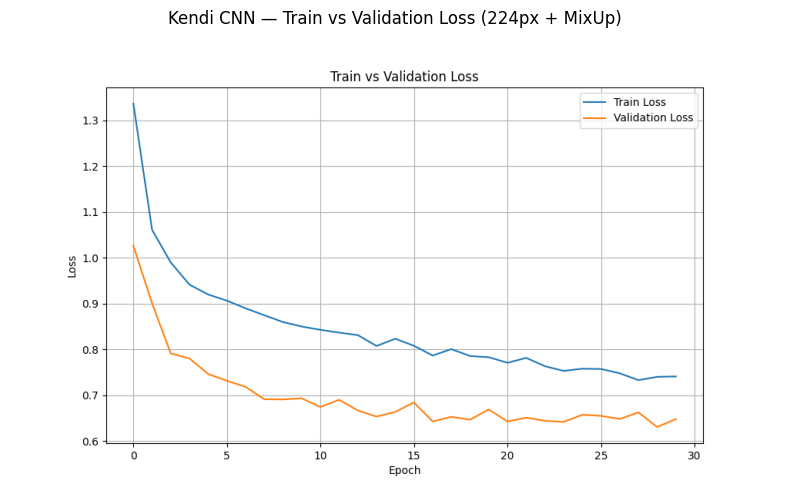

In [2]:
img = Image.open("loss_grafigi.png")
plt.figure(figsize=(10,6))
plt.imshow(img)
plt.axis('off')
plt.title("Kendi CNN — Train vs Validation Loss (224px + MixUp)")
plt.show()

## 2. ResNet50 (Transfer Learning + Fine-tuning)

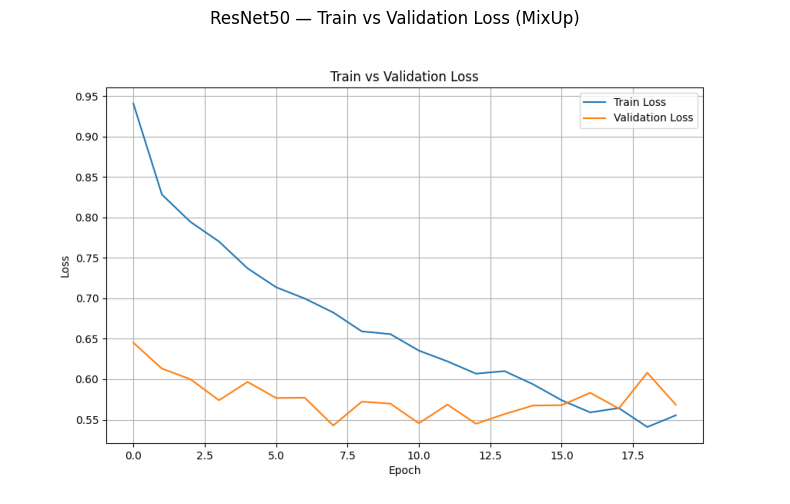

In [8]:
img = Image.open("loss_grafigi_resnet.png")
plt.figure(figsize=(10,6))
plt.imshow(img)
plt.axis('off')
plt.title("ResNet50 — Train vs Validation Loss (MixUp)")
plt.show()

## 3. EfficientNet-B0 (Transfer Learning + Fine-tuning)

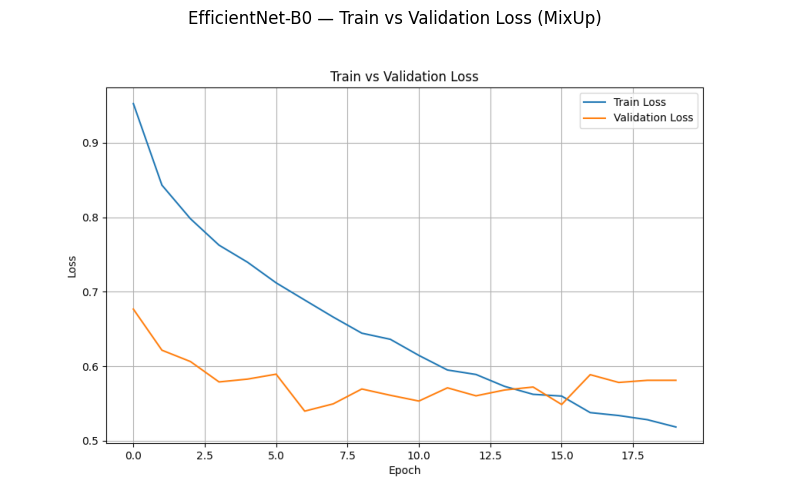

In [9]:
img = Image.open("loss_grafigi_efficientnet.png")
plt.figure(figsize=(10,6))
plt.imshow(img)
plt.axis('off')
plt.title("EfficientNet-B0 — Train vs Validation Loss (MixUp)")
plt.show()

## 4. Nihai Sonuç — Ensemble Confusion Matrix (3 Model Birleşimi)

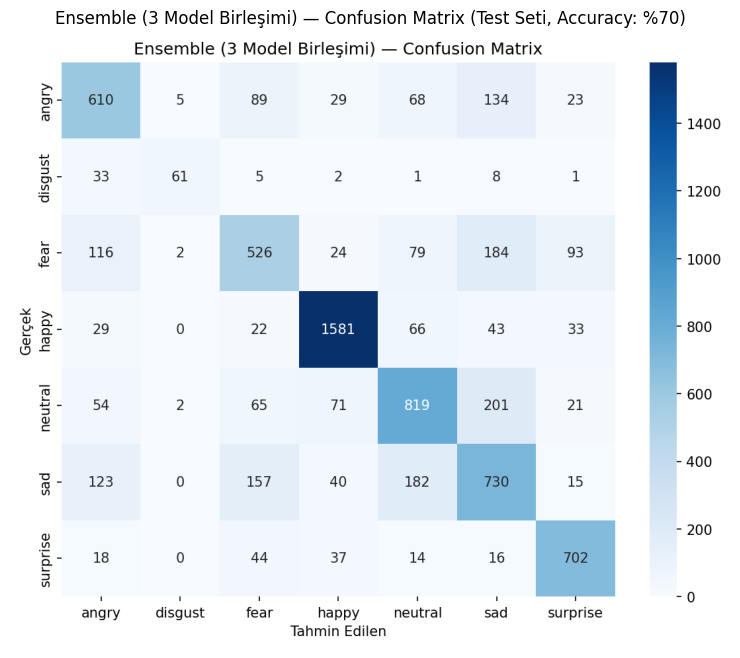

In [5]:
from PIL import Image

img = Image.open("ensemble_confusion_matrix.png")
plt.figure(figsize=(10,8))
plt.imshow(img)
plt.axis('off')
plt.title("Ensemble (3 Model Birleşimi) — Confusion Matrix (Test Seti, Accuracy: %70)")
plt.show()

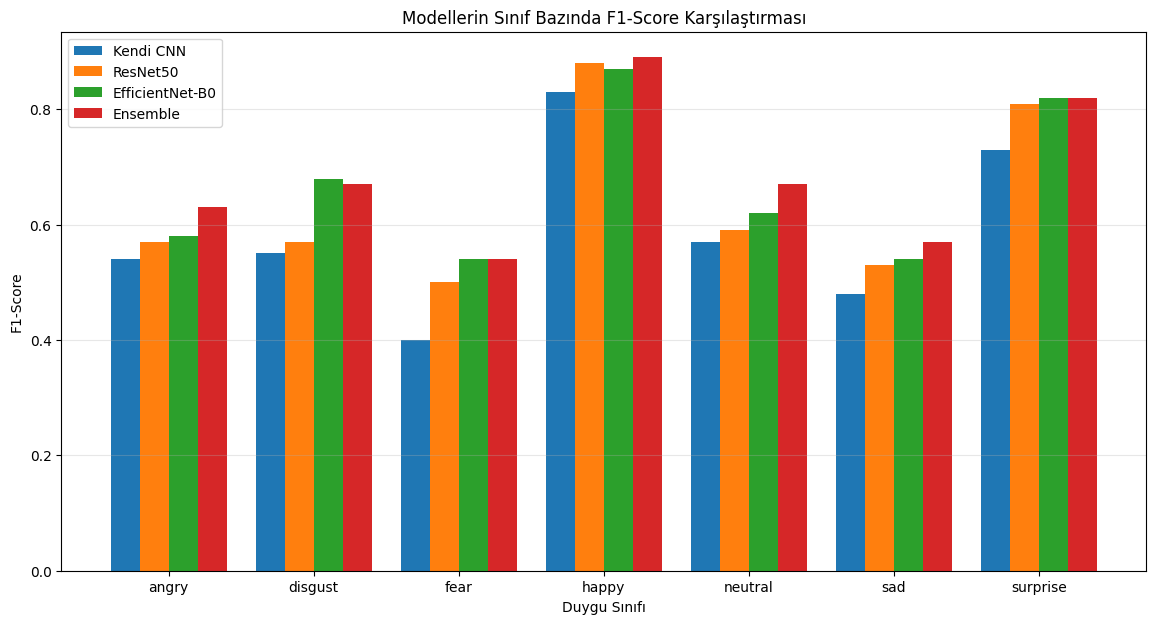

In [6]:
siniflar = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

f1_cnn =          [0.54, 0.55, 0.40, 0.83, 0.57, 0.48, 0.73]
f1_resnet =       [0.57, 0.57, 0.50, 0.88, 0.59, 0.53, 0.81]
f1_efficientnet = [0.58, 0.68, 0.54, 0.87, 0.62, 0.54, 0.82]
f1_ensemble =     [0.63, 0.67, 0.54, 0.89, 0.67, 0.57, 0.82]

x = np.arange(len(siniflar))
width = 0.2

plt.figure(figsize=(14, 7))
plt.bar(x - 1.5*width, f1_cnn, width, label='Kendi CNN')
plt.bar(x - 0.5*width, f1_resnet, width, label='ResNet50')
plt.bar(x + 0.5*width, f1_efficientnet, width, label='EfficientNet-B0')
plt.bar(x + 1.5*width, f1_ensemble, width, label='Ensemble')

plt.xlabel('Duygu Sınıfı')
plt.ylabel('F1-Score')
plt.title('Modellerin Sınıf Bazında F1-Score Karşılaştırması')
plt.xticks(x, siniflar)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.savefig("rapor_f1_karsilastirma.png", dpi=150, bbox_inches='tight')
plt.show()

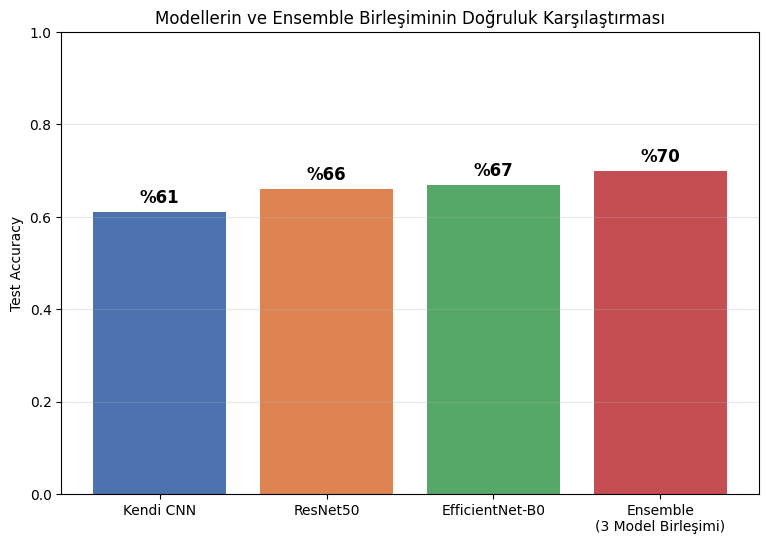

In [7]:
modeller = ['Kendi CNN', 'ResNet50', 'EfficientNet-B0', 'Ensemble\n(3 Model Birleşimi)']
accuracy_degerleri = [0.61, 0.66, 0.67, 0.70]

plt.figure(figsize=(9, 6))
renkler = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
bars = plt.bar(modeller, accuracy_degerleri, color=renkler)

plt.ylabel('Test Accuracy')
plt.title('Modellerin ve Ensemble Birleşiminin Doğruluk Karşılaştırması')
plt.ylim(0, 1)

for bar, val in zip(bars, accuracy_degerleri):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f'%{val*100:.0f}', 
              ha='center', fontsize=12, fontweight='bold')

plt.grid(axis='y', alpha=0.3)
plt.savefig("rapor_accuracy_karsilastirma.png", dpi=150, bbox_inches='tight')
plt.show()

## Sonuç ve Değerlendirme

Bu projede, FER2013 veri setinde duygu tanıma için 3 farklı model geliştirilip karşılaştırılmıştır:

- **Kendi CNN mimarim**, sıfırdan tasarlanmış 5 katmanlı bir evrişimli sinir ağı, **%61** test doğruluğuna ulaşmıştır.
- **ResNet50** (transfer learning + fine-tuning), **%66** test doğruluğu elde etmiştir.
- **EfficientNet-B0** (transfer learning + fine-tuning), ResNet50'nin 5'te 1'i kadar parametreyle **%67** test doğruluğuna ulaşarak en verimli tekil model olmuştur.
- Üç modelin tahmin olasılıklarının ortalamasıyla oluşturulan **Ensemble**, **%70** test doğruluğu ile projenin nihai ve en güçlü sonucunu vermiştir.

Kullanılan teknikler arasında Data Augmentation, Class Weighting, Batch Normalization, Dropout, MixUp, Focal Loss ve Ensemble Learning yer almaktadır. Sonuçlar, sistematik model geliştirme ve karşılaştırmalı değerlendirme sürecinin doğruluğu kayda değer ölçüde artırdığını göstermektedir.